<a href="https://colab.research.google.com/github/rivindu02/EN3160-Image-Processing-and-Computer-Vision/blob/main/Assignment02_Q4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

# --- Setup: Define File Paths in Google Drive ---
BASE_PATH = '/content/drive/My Drive/Colab Notebooks/graf/'
IMG1_PATH = BASE_PATH + 'img1.ppm'
IMG5_PATH = BASE_PATH + 'img5.ppm'
H_MATRIX_PATH = BASE_PATH + 'H1to5p'  # Homography matrix file



### Part (a): compute & Match SIFT Features

In [21]:
def load_and_display_images(img1_path, img5_path):
    """Load images and display them"""
    img1 = cv2.imread(img1_path)
    img5 = cv2.imread(img5_path)

    if img1 is None or img5 is None:
        raise ValueError("Could not load images. Check file paths.")

    # Convert BGR to RGB for display
    img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
    img5_rgb = cv2.cvtColor(img5, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    axes[0].imshow(img1_rgb)
    axes[0].set_title('Image 1 (Source)')
    axes[0].axis('off')
    axes[1].imshow(img5_rgb)
    axes[1].set_title('Image 5 (Target)')
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()

    return img1, img5

def compute_sift_features(img1, img5):
    """Compute SIFT features and match them"""
    # Convert to grayscale
    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray5 = cv2.cvtColor(img5, cv2.COLOR_BGR2GRAY)

    # Initialize SIFT detector
    sift = cv2.SIFT_create()

    # Detect keypoints and compute descriptors
    kp1, des1 = sift.detectAndCompute(gray1, None)
    kp5, des5 = sift.detectAndCompute(gray5, None)

    print(f"Number of keypoints in img1: {len(kp1)}")
    print(f"Number of keypoints in img5: {len(kp5)}")

    # Use FLANN-based matcher for better performance
    FLANN_INDEX_KDTREE = 1
    index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
    search_params = dict(checks=50)
    flann = cv2.FlannBasedMatcher(index_params, search_params)

    # Find matches using KNN (k=2 for ratio test)
    matches = flann.knnMatch(des1, des5, k=2)

    # Apply Lowe's ratio test to filter good matches
    good_matches = []
    for m, n in matches:
        if m.distance < 0.7 * n.distance:
            good_matches.append(m)

    print(f"Number of good matches: {len(good_matches)}")

    # Visualize matches
    img_matches = cv2.drawMatches(img1, kp1, img5, kp5, good_matches[:50], None,
                                   flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    plt.figure(figsize=(20, 10))
    plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
    plt.title(f'Top 50 SIFT Matches (out of {len(good_matches)} good matches)')
    plt.axis('off')
    plt.show()

    return kp1, kp5, good_matches

### Part (b): Compute Homography using RANSAC

In [22]:
def compute_homography_custom(src_pts, dst_pts):
    """
    Compute homography matrix H such that dst_pts = H * src_pts
    Uses Direct Linear Transform (DLT) method
    Requires at least 4 point correspondences
    """
    n = src_pts.shape[0]
    if n < 4:
        raise ValueError("Need at least 4 points to compute homography")

    # Build matrix A for DLT
    A = []
    for i in range(n):
        x, y = src_pts[i]
        u, v = dst_pts[i]
        A.append([-x, -y, -1, 0, 0, 0, u*x, u*y, u])
        A.append([0, 0, 0, -x, -y, -1, v*x, v*y, v])

    A = np.array(A)

    # Solve using SVD
    _, _, Vt = np.linalg.svd(A)
    H = Vt[-1].reshape(3, 3)

    # Normalize so that H[2,2] = 1
    H = H / H[2, 2]

    return H

def ransac_homography(kp1, kp5, matches, threshold=5.0, max_iterations=5000):
    """
    RANSAC algorithm to find best homography
    """
    # Extract matched point coordinates
    src_pts = np.float32([kp1[m.queryIdx].pt for m in matches])
    dst_pts = np.float32([kp5[m.trainIdx].pt for m in matches])

    best_H = None
    best_inliers = []
    max_inlier_count = 0

    n_points = len(matches)

    for iteration in range(max_iterations):
        # Randomly select 4 points
        sample_indices = random.sample(range(n_points), 4)
        src_sample = src_pts[sample_indices]
        dst_sample = dst_pts[sample_indices]

        try:
            # Compute homography from these 4 points
            H = compute_homography_custom(src_sample, dst_sample)

            # Transform all source points
            src_pts_homogeneous = np.hstack([src_pts, np.ones((n_points, 1))])
            transformed_pts = (H @ src_pts_homogeneous.T).T

            # Convert from homogeneous to Cartesian coordinates
            transformed_pts = transformed_pts[:, :2] / transformed_pts[:, 2:]

            # Compute distances (reprojection error)
            distances = np.linalg.norm(dst_pts - transformed_pts, axis=1)

            # Count inliers
            inliers = np.where(distances < threshold)[0]
            inlier_count = len(inliers)

            # Update best model if this is better
            if inlier_count > max_inlier_count:
                max_inlier_count = inlier_count
                best_inliers = inliers
                best_H = H

        except:
            # Skip if homography computation fails
            continue

    # Refine homography using all inliers
    if len(best_inliers) >= 4:
        src_inliers = src_pts[best_inliers]
        dst_inliers = dst_pts[best_inliers]
        best_H = compute_homography_custom(src_inliers, dst_inliers)

    print(f"\nRANSAC Results:")
    print(f"Total matches: {n_points}")
    print(f"Inliers: {max_inlier_count}")
    print(f"Inlier ratio: {max_inlier_count/n_points:.2%}")

    return best_H, best_inliers, src_pts, dst_pts

def load_ground_truth_homography(h_path):
    """Load the ground truth homography matrix from dataset"""
    try:
        H_gt = np.loadtxt(h_path)
        return H_gt
    except:
        print("Could not load ground truth homography matrix")
        return None

def compare_homographies(H_custom, H_gt):
    """Compare computed homography with ground truth"""
    if H_gt is None:
        print("No ground truth available for comparison")
        return

    print("\n" + "="*60)
    print("HOMOGRAPHY COMPARISON")
    print("="*60)

    print("\nComputed Homography (RANSAC):")
    print(H_custom)

    print("\nGround Truth Homography:")
    print(H_gt)

    print("\nDifference:")
    print(H_custom - H_gt)

    # Compute Frobenius norm of difference
    frobenius_norm = np.linalg.norm(H_custom - H_gt, 'fro')
    print(f"\nFrobenius norm of difference: {frobenius_norm:.6f}")

    # Normalize both matrices for fair comparison
    H_custom_norm = H_custom / H_custom[2, 2]
    H_gt_norm = H_gt / H_gt[2, 2]
    normalized_diff = np.linalg.norm(H_custom_norm - H_gt_norm, 'fro')
    print(f"Normalized Frobenius norm: {normalized_diff:.6f}")

 ### Part (c): Stitch IMG1 onto IMG5

In [23]:
def stitch_images(img1, img5, H):
    """Stitch img1 onto img5 using homography H"""
    h1, w1 = img1.shape[:2]
    h5, w5 = img5.shape[:2]

    # Get corners of img1
    corners_img1 = np.float32([[0, 0], [w1, 0], [w1, h1], [0, h1]]).reshape(-1, 1, 2)

    # Transform corners to img5 coordinate system
    corners_transformed = cv2.perspectiveTransform(corners_img1, H)

    # Combine with img5 corners to find bounding box
    corners_img5 = np.float32([[0, 0], [w5, 0], [w5, h5], [0, h5]]).reshape(-1, 1, 2)
    all_corners = np.concatenate((corners_transformed, corners_img5), axis=0)

    # Find bounding box
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    # Translation to bring everything into positive coordinates
    translation = np.array([[1, 0, -x_min],
                           [0, 1, -y_min],
                           [0, 0, 1]])

    # Warp img1 with translation
    output_size = (x_max - x_min, y_max - y_min)
    img1_warped = cv2.warpPerspective(img1, translation @ H, output_size)

    # Create output canvas and place img5
    result = np.zeros((y_max - y_min, x_max - x_min, 3), dtype=np.uint8)
    result[-y_min:-y_min + h5, -x_min:-x_min + w5] = img5

    # Blend images - simple approach: use img1_warped where it exists
    mask = (img1_warped > 0).any(axis=2)
    result[mask] = img1_warped[mask]

    return result

def stitch_with_blending(img1, img5, H):
    """Advanced stitching with alpha blending"""
    h1, w1 = img1.shape[:2]
    h5, w5 = img5.shape[:2]

    # Get corners of img1
    corners_img1 = np.float32([[0, 0], [w1, 0], [w1, h1], [0, h1]]).reshape(-1, 1, 2)
    corners_transformed = cv2.perspectiveTransform(corners_img1, H)

    # Combine with img5 corners
    corners_img5 = np.float32([[0, 0], [w5, 0], [w5, h5], [0, h5]]).reshape(-1, 1, 2)
    all_corners = np.concatenate((corners_transformed, corners_img5), axis=0)

    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    translation = np.array([[1, 0, -x_min],
                           [0, 1, -y_min],
                           [0, 0, 1]])

    output_size = (x_max - x_min, y_max - y_min)

    # Warp img1
    img1_warped = cv2.warpPerspective(img1, translation @ H, output_size)

    # Create masks
    mask1 = cv2.warpPerspective(np.ones((h1, w1), dtype=np.float32),
                                 translation @ H, output_size)

    # Place img5 in result
    result = np.zeros((y_max - y_min, x_max - x_min, 3), dtype=np.float32)
    mask5 = np.zeros((y_max - y_min, x_max - x_min), dtype=np.float32)

    y_start, x_start = -y_min, -x_min
    result[y_start:y_start + h5, x_start:x_start + w5] = img5.astype(np.float32)
    mask5[y_start:y_start + h5, x_start:x_start + w5] = 1.0

    # Alpha blending in overlap region
    overlap = (mask1 > 0) & (mask5 > 0)
    result[mask1 > 0] = img1_warped[mask1 > 0].astype(np.float32)

    # Simple average in overlap
    result[overlap] = (img1_warped[overlap].astype(np.float32) +
                       result[overlap]) / 2.0

    return result.astype(np.uint8)

### Main Execution

IMAGE STITCHING WITH SIFT AND RANSAC

Loading images...


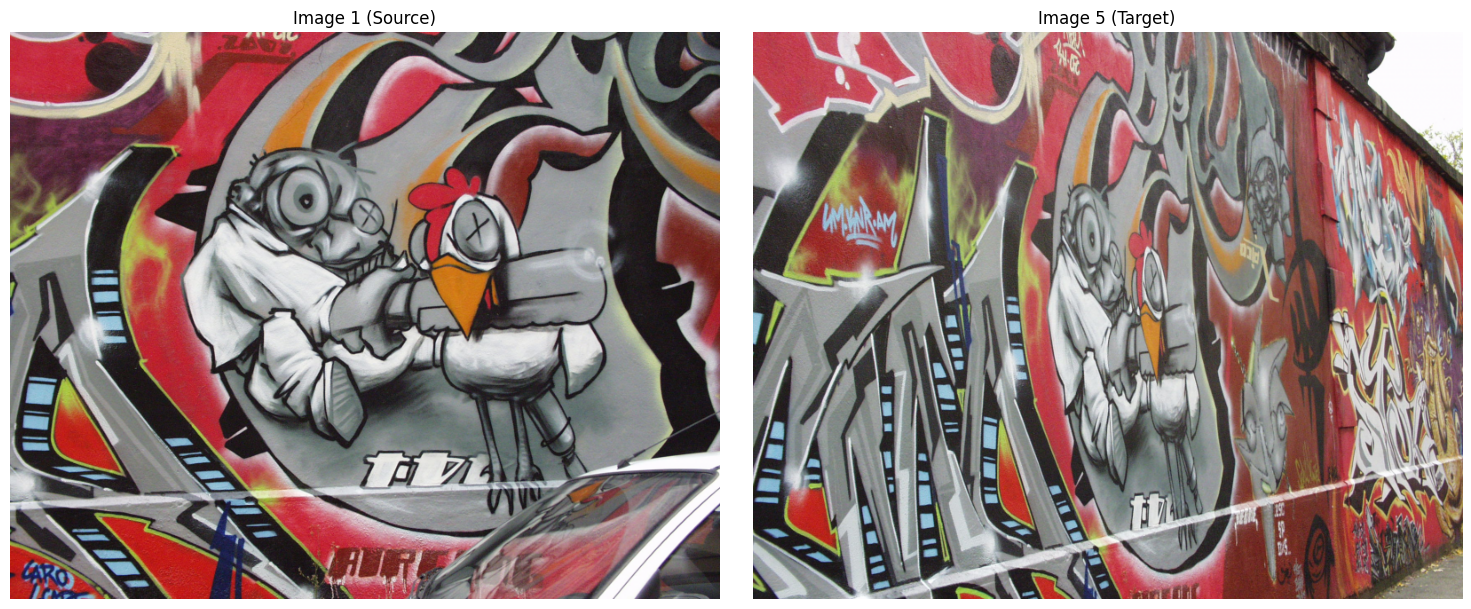


PART (a): SIFT FEATURE DETECTION AND MATCHING
Number of keypoints in img1: 2674
Number of keypoints in img5: 3923
Number of good matches: 40


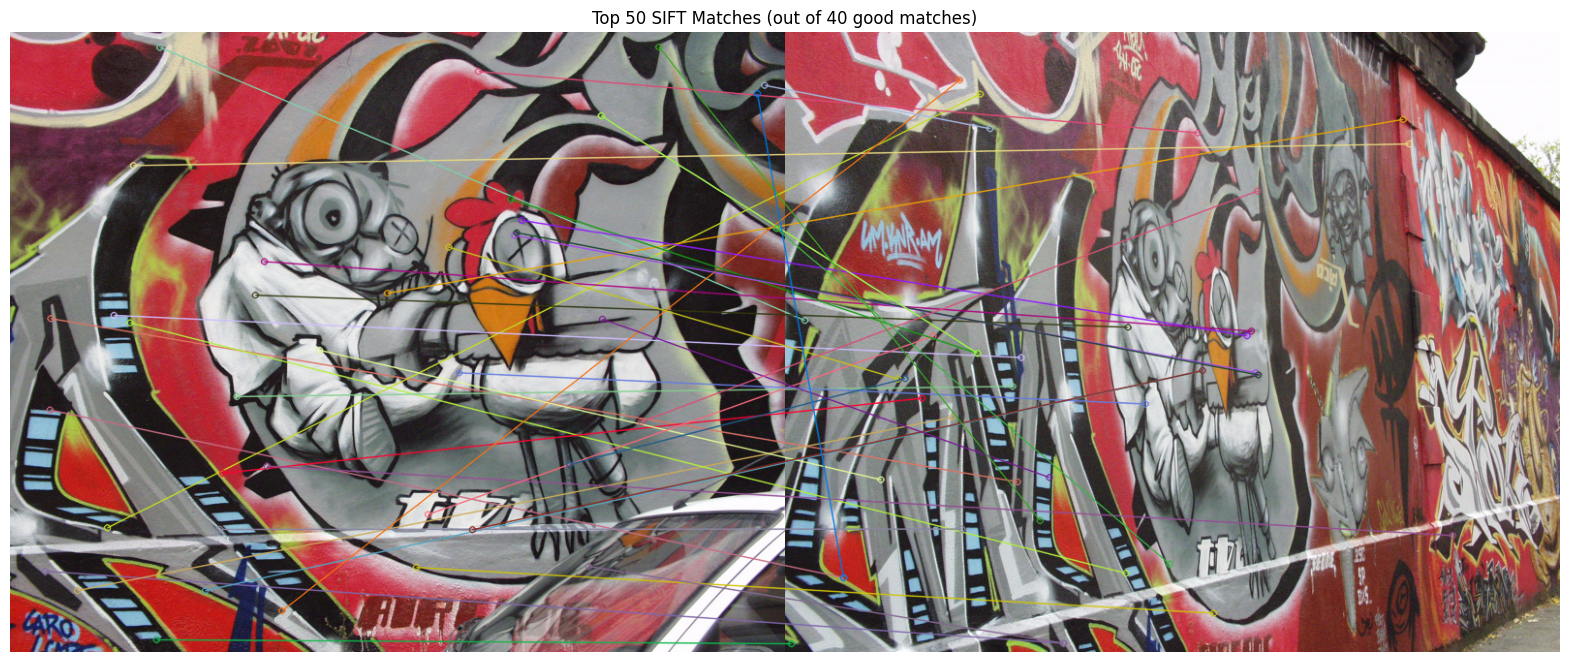


PART (b): HOMOGRAPHY COMPUTATION WITH RANSAC

RANSAC Results:
Total matches: 40
Inliers: 7
Inlier ratio: 17.50%

Computed Homography Matrix:
[[-6.50423618e-01 -4.17870748e-01  4.31873097e+02]
 [-5.27077298e-01 -3.37273733e-01  3.49197613e+02]
 [-1.50974531e-03 -9.65576068e-04  1.00000000e+00]]

HOMOGRAPHY COMPARISON

Computed Homography (RANSAC):
[[-6.50423618e-01 -4.17870748e-01  4.31873097e+02]
 [-5.27077298e-01 -3.37273733e-01  3.49197613e+02]
 [-1.50974531e-03 -9.65576068e-04  1.00000000e+00]]

Ground Truth Homography:
[[ 6.2544644e-01  5.7759174e-02  2.2201217e+02]
 [ 2.2240536e-01  1.1652147e+00 -2.5605611e+01]
 [ 4.9212545e-04 -3.6542424e-05  1.0000000e+00]]

Difference:
[[-1.27587006e+00 -4.75629922e-01  2.09860927e+02]
 [-7.49482658e-01 -1.50248843e+00  3.74803224e+02]
 [-2.00187076e-03 -9.29033644e-04  0.00000000e+00]]

Frobenius norm of difference: 429.562264
Normalized Frobenius norm: 429.562264


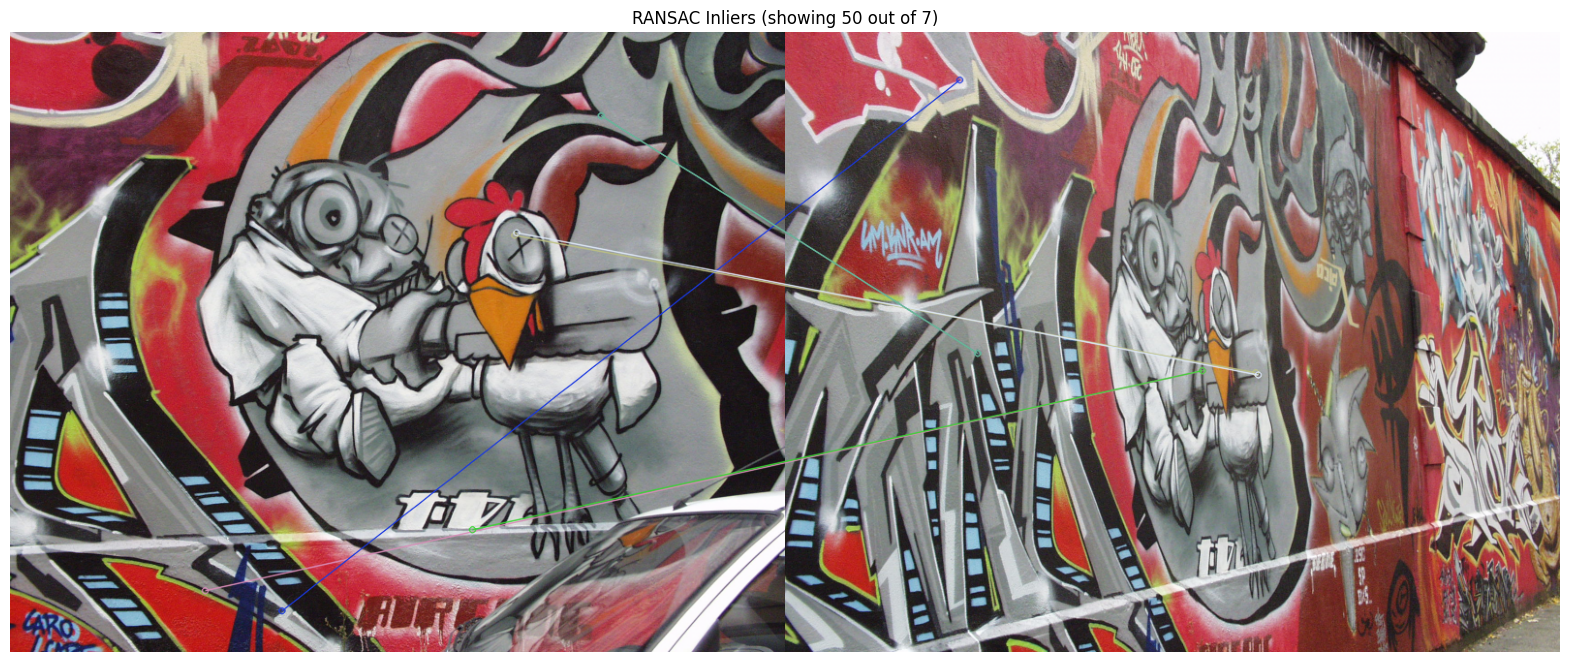


PART (c): IMAGE STITCHING

Stitching img1 onto img5...

Stitching with ground truth homography for comparison...


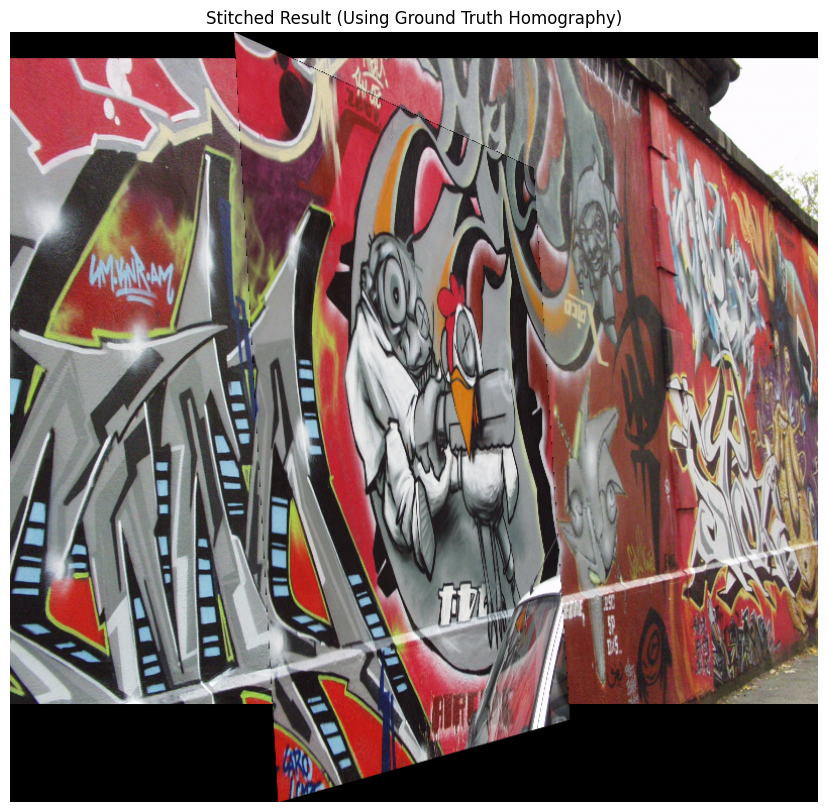


PROCESSING COMPLETE!


In [24]:
def main():
    print("="*60)
    print("IMAGE STITCHING WITH SIFT AND RANSAC")
    print("="*60)

    # Load and display images
    print("\nLoading images...")
    img1, img5 = load_and_display_images(IMG1_PATH, IMG5_PATH)

    # Part (a): Compute and match SIFT features
    print("\n" + "="*60)
    print("PART (a): SIFT FEATURE DETECTION AND MATCHING")
    print("="*60)
    kp1, kp5, good_matches = compute_sift_features(img1, img5)

    # Part (b): Compute homography with RANSAC
    print("\n" + "="*60)
    print("PART (b): HOMOGRAPHY COMPUTATION WITH RANSAC")
    print("="*60)
    H_custom, inliers, src_pts, dst_pts = ransac_homography(kp1, kp5, good_matches)

    print("\nComputed Homography Matrix:")
    print(H_custom)

    # Load and compare with ground truth
    H_gt = load_ground_truth_homography(H_MATRIX_PATH)
    compare_homographies(H_custom, H_gt)

    # Visualize inliers
    inlier_matches = [good_matches[i] for i in inliers]
    img_inliers = cv2.drawMatches(img1, kp1, img5, kp5, inlier_matches[:50], None,
                                   flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(20, 10))
    plt.imshow(cv2.cvtColor(img_inliers, cv2.COLOR_BGR2RGB))
    plt.title(f'RANSAC Inliers (showing 50 out of {len(inliers)})')
    plt.axis('off')
    plt.show()

    # Part (c): Stitch images
    print("\n" + "="*60)
    print("PART (c): IMAGE STITCHING")
    print("="*60)

    print("\nStitching img1 onto img5...")

    # Simple stitching
    #result_simple = stitch_images(img1, img5, H_custom)

    # Stitching with blending
    # result_blended = stitch_with_blending(img1, img5, H_custom)

    # # Display results
    # fig, axes = plt.subplots(2, 1, figsize=(20, 15))

    # axes[0].imshow(cv2.cvtColor(result_simple, cv2.COLOR_BGR2RGB))
    # axes[0].set_title('Stitched Result (Simple)')
    # axes[0].axis('off')

    # axes[1].imshow(cv2.cvtColor(result_blended, cv2.COLOR_BGR2RGB))
    # axes[1].set_title('Stitched Result (With Blending)')
    # axes[1].axis('off')

    # plt.tight_layout()
    # plt.show()

    # Also use ground truth if available
    if H_gt is not None:
        print("\nStitching with ground truth homography for comparison...")
        result_gt = stitch_with_blending(img1, img5, H_gt)

        plt.figure(figsize=(20, 10))
        plt.imshow(cv2.cvtColor(result_gt, cv2.COLOR_BGR2RGB))
        plt.title('Stitched Result (Using Ground Truth Homography)')
        plt.axis('off')
        plt.show()

    print("\n" + "="*60)
    print("PROCESSING COMPLETE!")
    print("="*60)

# Run the main function
if __name__ == "__main__":
    main()